In [9]:
df = pd.read_csv("../data/raw/ai4i2020.csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [10]:
df.head()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Libraries imported successfully!")

Libraries imported successfully!


In [5]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

Dataset Shape: (10000, 14)

Column Names:
['UDI', 'Product ID', 'Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF']

Data Types:
UDI                          int64
Product ID                     str
Type                           str
Air temperature [K]        float64
Process temperature [K]    float64
Rotational speed [rpm]       int64
Torque [Nm]                float64
Tool wear [min]              int64
Machine failure              int64
TWF                          int64
HDF                          int64
PWF                          int64
OSF                          int64
RNF                          int64
dtype: object


In [11]:
missing = df.isnull().sum()

print("Missing values in each column:")
print(missing)

print("\nTotal missing values:", missing.sum())

Missing values in each column:
UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0
dtype: int64

Total missing values: 0


In [12]:
duplicates = df.duplicated().sum()

print("Duplicate rows:", duplicates)

Duplicate rows: 0


checking datatypes and invalid catogories

In [13]:
df.info()
print(df["Type"].value_counts())

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  str    
 2   Type                     10000 non-null  str    
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes: float64(3), int64(9), str(2)
me

checking binary target/failure columns.

In [14]:
binary_columns = [
    "Machine failure",
    "TWF",
    "HDF",
    "PWF",
    "OSF",
    "RNF"
]

for col in binary_columns:
    print(f"\n{col}")
    print(df[col].value_counts())


Machine failure
Machine failure
0    9661
1     339
Name: count, dtype: int64

TWF
TWF
0    9954
1      46
Name: count, dtype: int64

HDF
HDF
0    9885
1     115
Name: count, dtype: int64

PWF
PWF
0    9905
1      95
Name: count, dtype: int64

OSF
OSF
0    9902
1      98
Name: count, dtype: int64

RNF
RNF
0    9981
1      19
Name: count, dtype: int64


checking class imbalance

In [15]:
failure_counts = df["Machine failure"].value_counts()

print(failure_counts)

print("\nPercentage:")
print(df["Machine failure"].value_counts(normalize=True) * 100)

Machine failure
0    9661
1     339
Name: count, dtype: int64

Percentage:
Machine failure
0    96.61
1     3.39
Name: proportion, dtype: float64


In [16]:
numeric_features = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

df[numeric_features].describe().T

,count,mean,std,min,25%,50%,75%,max
Air temperature [K],10000.0,300.00493,2.000259,295.3,298.3,300.1,301.5,304.5
Process temperature [K],10000.0,310.00556,1.483734,305.7,308.8,310.1,311.1,313.8
Rotational speed [rpm],10000.0,1538.77610,179.284096,1168.0,1423.0,1503.0,1612.0,2886.0
Torque [Nm],10000.0,39.98691,9.968934,3.8,33.2,40.1,46.8,76.6
Tool wear [min],10000.0,107.95100,63.654147,0.0,53.0,108.0,162.0,253.0


visualising the target imbalance

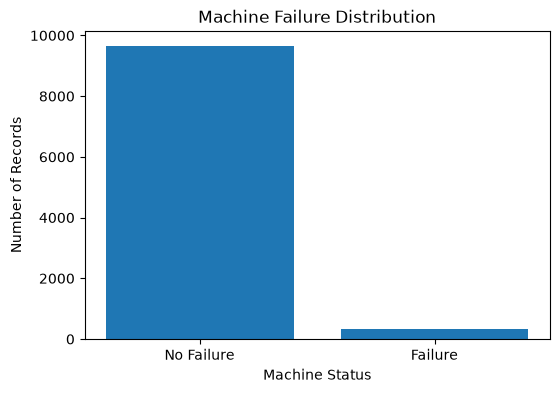

In [17]:
import matplotlib.pyplot as plt

counts = df["Machine failure"].value_counts().sort_index()

plt.figure(figsize=(6, 4))
plt.bar(["No Failure", "Failure"], counts.values)

plt.title("Machine Failure Distribution")
plt.ylabel("Number of Records")
plt.xlabel("Machine Status")

plt.show()

checking correlation


In [18]:
correlation_columns = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]",
    "Machine failure"
]

correlation_matrix = df[correlation_columns].corr()

correlation_matrix

,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure
Air temperature [K],1.000000,0.876107,0.022670,-0.013778,0.013853,0.082556
Process temperature [K],0.876107,1.000000,0.019277,-0.014061,0.013488,0.035946
Rotational speed [rpm],0.022670,0.019277,1.000000,-0.875027,0.000223,-0.044188
Torque [Nm],-0.013778,-0.014061,-0.875027,1.000000,-0.003093,0.191321
Tool wear [min],0.013853,0.013488,0.000223,-0.003093,1.000000,0.105448
Machine failure,0.082556,0.035946,-0.044188,0.191321,0.105448,1.000000


again visualizing

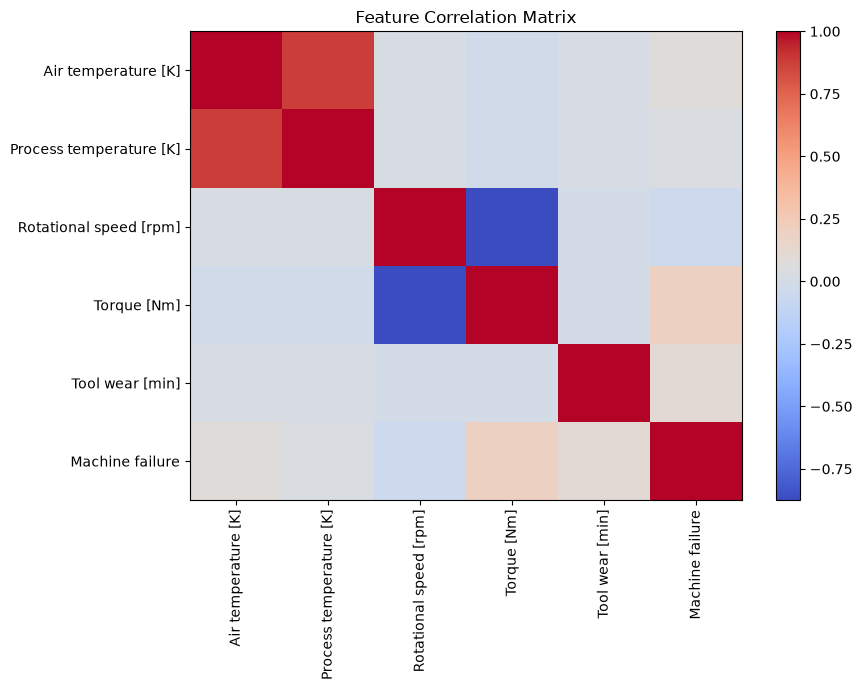

In [19]:
plt.figure(figsize=(9, 7))

plt.imshow(correlation_matrix, cmap="coolwarm", aspect="auto")
plt.colorbar()

plt.xticks(
    range(len(correlation_columns)),
    correlation_columns,
    rotation=90
)

plt.yticks(
    range(len(correlation_columns)),
    correlation_columns
)

plt.title("Feature Correlation Matrix")
plt.tight_layout()
plt.show()

compare feature for failurevs normal

In [20]:
df.groupby("Machine failure")[numeric_features].mean().T 

Machine failure,0,1
Air temperature [K],299.973999,300.886431
Process temperature [K],309.995570,310.290265
Rotational speed [rpm],1540.260014,1496.486726
Torque [Nm],39.629655,50.168142
Tool wear [min],106.693717,143.781711


some checks

In [21]:
print("Shape:", df.shape)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

print("\nMachine Failure Counts:")
print(df["Machine failure"].value_counts())

print("\nMachine Failure Percentage:")
print(df["Machine failure"].value_counts(normalize=True) * 100)

print("\nProduct Types:")
print(df["Type"].value_counts())

Shape: (10000, 14)

Missing Values:
UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0
dtype: int64

Duplicate Rows:
0

Machine Failure Counts:
Machine failure
0    9661
1     339
Name: count, dtype: int64

Machine Failure Percentage:
Machine failure
0    96.61
1     3.39
Name: proportion, dtype: float64

Product Types:
Type
L    6000
M    2997
H    1003
Name: count, dtype: int64


In [22]:
df[numeric_features].describe().T

,count,mean,std,min,25%,50%,75%,max
Air temperature [K],10000.0,300.00493,2.000259,295.3,298.3,300.1,301.5,304.5
Process temperature [K],10000.0,310.00556,1.483734,305.7,308.8,310.1,311.1,313.8
Rotational speed [rpm],10000.0,1538.77610,179.284096,1168.0,1423.0,1503.0,1612.0,2886.0
Torque [Nm],10000.0,39.98691,9.968934,3.8,33.2,40.1,46.8,76.6
Tool wear [min],10000.0,107.95100,63.654147,0.0,53.0,108.0,162.0,253.0


comparision of normal vs failed cases

In [23]:
df.groupby("Machine failure")[numeric_features].mean().T

Machine failure,0,1
Air temperature [K],299.973999,300.886431
Process temperature [K],309.995570,310.290265
Rotational speed [rpm],1540.260014,1496.486726
Torque [Nm],39.629655,50.168142
Tool wear [min],106.693717,143.781711


inspecting the indivisual failure modes

In [24]:
failure_modes = ["TWF", "HDF", "PWF", "OSF", "RNF"]

for col in failure_modes:
    print(f"\n{col}:")
    print(df[col].value_counts())


TWF:
TWF
0    9954
1      46
Name: count, dtype: int64

HDF:
HDF
0    9885
1     115
Name: count, dtype: int64

PWF:
PWF
0    9905
1      95
Name: count, dtype: int64

OSF:
OSF
0    9902
1      98
Name: count, dtype: int64

RNF:
RNF
0    9981
1      19
Name: count, dtype: int64


checking whether machine failure and the indivisual failure labels are consistent 

In [25]:
failure_modes = ["TWF", "HDF", "PWF", "OSF", "RNF"]

df["Failure Mode Count"] = df[failure_modes].sum(axis=1)

print(
    df.groupby(["Machine failure", "Failure Mode Count"])
      .size()
)

Machine failure  Failure Mode Count
0                0                     9643
                 1                       18
1                0                        9
                 1                      306
                 2                       23
                 3                        1
dtype: int64
